# The object graph: nodes and edges

Shows one run's graph: every node (one object: the masks that `graph/pipeline.py` matched to it by DINO appearance and
location) as its 3D box, the union of every view of it, and the edges between them (`graph/edges.py`):

- **on**: one object rests on or in another, such as a cushion on a sofa. Drawn as an arrow from the object on top.
- **near**: the two boxes are at most 25 cm apart. Drawn as a dashed line.

Walls, floors, ceilings and nodes with a box side over 3 m get no edges and aren't drawn.

Set the run in the first cell, then run the pipeline from the second (`run.py`): it only computes the stages that
aren't cached yet, so a rerun is quick. The rest reads its cached stages.

In [ ]:
import subprocess
import sys
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)  # torch.jit, via transformers

from collections import Counter

from graph import edges as graph_edges
from graph import plot_edges
from utils import footage
from utils.config import ROOT_DIR

SOURCE = "replica/room_0/00"  # or phone/<name> for a phone run
STRIDE = 20
MASK_SOURCE = "sam3"  # or "gt" for the GT masks
POSE_SOURCE = None  # None: Replica's poses on Replica, VGGT-Omega's on phone video

run = footage.make_run(SOURCE, STRIDE, MASK_SOURCE, POSE_SOURCE, "")
args = ["--source", SOURCE, "--stride", str(STRIDE), "--mask-source", MASK_SOURCE]
if POSE_SOURCE:
    args += ["--pose-source", POSE_SOURCE]


def sh(*command: str) -> None:
    """Run a command in the repository and show its output here, without warnings and progress bars."""
    proc = subprocess.Popen(
        [sys.executable, *command], cwd=ROOT_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
    )
    noise = ("Warning", "warnings.warn", "[transformers]", "Loading weights", "it/s]", "s/it]", "from_numpy")
    for line in proc.stdout:
        if line.strip() and not any(n in line for n in noise):
            print(line, end="")
    if proc.wait():
        raise RuntimeError(f"{command[0]} failed")

## Run the pipeline

`run.py` computes the stages that aren't cached yet (SAM 3 masks, DINO and SigLIP embeddings, 3D boxes, the graph) and,
on Replica, prints the score tables. With everything cached it only rebuilds what changed, such as the graph after an
edit to `configs/association.json`. `EXTRA` adds options:

- `["--overwrite", "graph"]`: rebuild the graph even if it is cached
- `["--graph-only"]`: only rebuild the graph from the cached stages, without loading any model or scoring it
- `["--association-config", "configs/my_config.json"]`: other matching parameters

In [ ]:
EXTRA = []

sh("run.py", *args, *EXTRA)

In [ ]:
nodes, edges = plot_edges.load_graph(run)
counts = Counter(e.relation for e in edges)
print(f"{run.source}: {len(nodes)} nodes, {len(edges)} edges ({counts['on']} on, {counts['near']} near)")

## One node, all its views

The graph takes the masks one frame at a time. Each mask (or group of overlapping masks in one frame) is scored against
every object in memory by **DINO appearance** and **location**, and joins the best one when both agree; otherwise it
becomes a new object. The object's **box is the union** of every box it was matched with, so it grows as views show
more of the object, also parts hidden in other views, and never shrinks.

Pick a node below, or leave `NODE = None` for the node seen in the most frames that holds more than one SAM ID.

In [9]:
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches

from utils.schema import Boxes, Graph, Masks, load_stage

masks = load_stage(run.stage_dir("masks"), Masks)
boxes = load_stage(run.stage_dir("boxes"), Boxes)
node_of_mask = load_stage(run.stage_dir("graph"), Graph).node
matches = json.loads((run.stage_dir("graph") / "matches.json").read_text())
print(f"{len(masks.frame)} masks in {len(np.unique(masks.frame))} frames: {len(np.unique(masks.sam_id))} SAM IDs, "
      f"{len(nodes)} nodes")

NODE = None
if NODE is None:
    NODE = max((n for n in nodes if len(n.sam_ids) > 1), key=lambda n: len(n.frames)).id
node = nodes[NODE]
print(f"node {NODE}: {node.label}, seen in {len(node.frames)} frames ({node.frames[0]}-{node.frames[-1]}), "
      f"SAM IDs {node.sam_ids}")

4090 masks in 100 frames: 101 SAM IDs, 453 nodes
node 103: indoor-plant, seen in 58 frames (620-1880), SAM IDs [63, 64]


### How the box grows

Left: the size of the node's box along x, y and z after each frame (solid, the union so far) and the size of that
frame's view alone (dotted). The union only grows. Right: from above, every view's box (thin, coloured by SAM ID) and
the node's box (thick black), the union of them all.

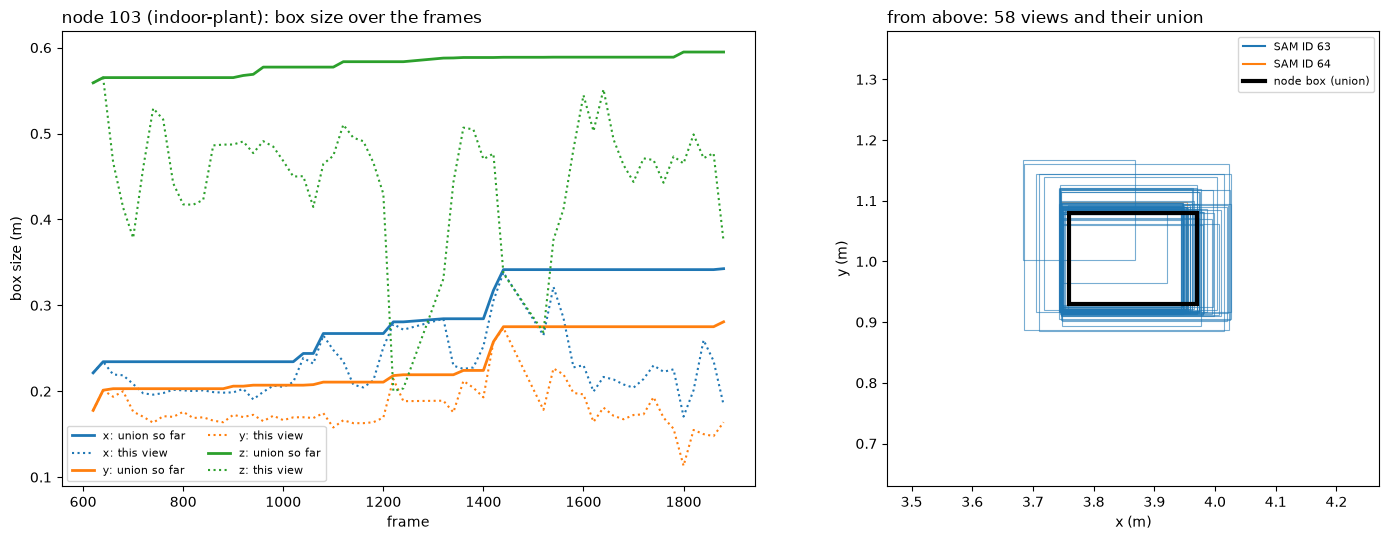

In [10]:
rows = node.rows[boxes.n_points[node.rows] > 0]
rows = rows[np.argsort(masks.frame[rows], kind="stable")]
frames = masks.frame[rows]
union_lo = np.minimum.accumulate(boxes.box_min[rows], axis=0)
union_hi = np.maximum.accumulate(boxes.box_max[rows], axis=0)
track_colour = {t: plt.cm.tab10(k % 10) for k, t in enumerate(node.sam_ids)}

fig, (ax_size, ax_top) = plt.subplots(1, 2, figsize=(15, 5.5))
for k, axis in enumerate("xyz"):
    ax_size.plot(frames, union_hi[:, k] - union_lo[:, k], color=f"C{k}", lw=2, label=f"{axis}: union so far")
    ax_size.plot(frames, boxes.box_max[rows, k] - boxes.box_min[rows, k], color=f"C{k}", ls=":", label=f"{axis}: this view")
ax_size.set_xlabel("frame")
ax_size.set_ylabel("box size (m)")
ax_size.set_title(f"node {NODE} ({node.label}): box size over the frames", loc="left")
ax_size.legend(ncol=2, fontsize=8)

for r in rows:
    (x0, y0), (x1, y1) = boxes.box_min[r, :2], boxes.box_max[r, :2]
    ax_top.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=0.8, alpha=0.6,
                                       edgecolor=track_colour[int(masks.sam_id[r])]))
(x0, y0), (x1, y1) = node.box_min[:2], node.box_max[:2]
ax_top.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=3, edgecolor="k"))
for t, c in track_colour.items():
    ax_top.plot([], [], color=c, label=f"SAM ID {t}")
ax_top.plot([], [], color="k", lw=3, label="node box (union)")
pad = 0.3
ax_top.set_xlim(x0 - pad, x1 + pad)
ax_top.set_ylim(y0 - pad, y1 + pad)
ax_top.set_aspect("equal")
ax_top.set_xlabel("x (m)")
ax_top.set_ylabel("y (m)")
ax_top.set_title(f"from above: {len(rows)} views and their union", loc="left")
ax_top.legend(fontsize=8)
fig.tight_layout()

### The node in four of its frames

The node's masks outlined in red, in frames spread over the time it is seen; the rest of the frame is dimmed.

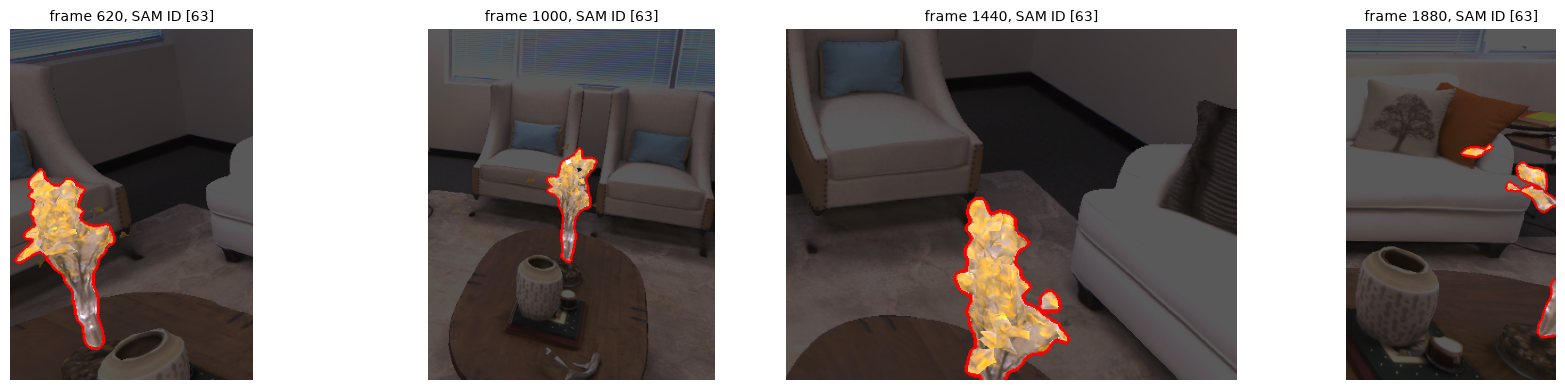

In [11]:
import pycocotools.mask as mask_utils
from scipy.ndimage import binary_dilation

from utils import footage


def show_mask(ax, frame, rows, title, margin=150):
    """The frame zoomed on the masks in rows, with everything else dimmed and the masks outlined in red."""
    image = footage.load_rgb(run, int(frame)).astype(np.float32)
    mask = mask_utils.decode(mask_utils.merge([masks.rle[r] for r in rows])).astype(bool)
    image[~mask] *= 0.35
    image[binary_dilation(mask, iterations=3) & ~mask] = (255, 0, 0)
    v, u = np.nonzero(mask)
    y0, y1 = max(v.min() - margin, 0), min(v.max() + margin, image.shape[0])
    x0, x1 = max(u.min() - margin, 0), min(u.max() + margin, image.shape[1])
    ax.imshow(image[y0:y1, x0:x1].astype(np.uint8))
    ax.set_title(title, fontsize=10)
    ax.axis("off")


shown = node.frames[np.linspace(0, len(node.frames) - 1, min(4, len(node.frames))).astype(int)]
fig, axes = plt.subplots(1, len(shown), figsize=(4.5 * len(shown), 4))
for ax, frame in zip(np.atleast_1d(axes), shown, strict=True):
    rows_here = np.flatnonzero((masks.frame == frame) & (node_of_mask == NODE))
    show_mask(ax, frame, rows_here, f"frame {frame}, SAM ID {sorted(set(masks.sam_id[rows_here].tolist()))}")
fig.tight_layout()

## SAM IDs merged into one node

SAM gives an object a new ID when it loses track of it, or when another prompt finds it too. The graph ignores those
IDs: what decides is whether DINO and location agree. For each SAM ID in the node: the frame it first joined, and the
scores of that match (DINO cosine against the node's stored views, box overlap and centre closeness, and the total,
which must be above the threshold).

In [12]:
threshold = json.loads((run.stage_dir("graph") / "metadata.json").read_text())["config"]["threshold"]
print(f"node {NODE} ({node.label}), threshold {threshold}")
print(f"{'SAM ID':>7} {'first frame':>12}  {'DINO':>5} {'IoU':>5} {'centre':>6} {'score':>6}")
first = {}
for m in matches:
    if m["object_id"] != NODE:
        continue
    for t in m["sam_ids"]:
        first.setdefault(t, m)
for t, m in sorted(first.items(), key=lambda kv: kv[1]["frame"]):
    s = m["scores"]
    if not m["matched"]:
        print(f"{t:>7} {m['frame']:>12}  started the node")
    else:
        print(f"{t:>7} {m['frame']:>12}  {s['dino']:>5.2f} {s['iou']:>5.2f} {s['center']:>6.2f} {s['score']:>6.2f}")

node 103 (indoor-plant), threshold 0.55
 SAM ID  first frame   DINO   IoU centre  score
     63          620  started the node
     64          700   0.84  0.52   0.95   0.79


### One frame of each SAM ID

Each SAM ID's mask in the first frame it joined the node: different SAM IDs, one object.

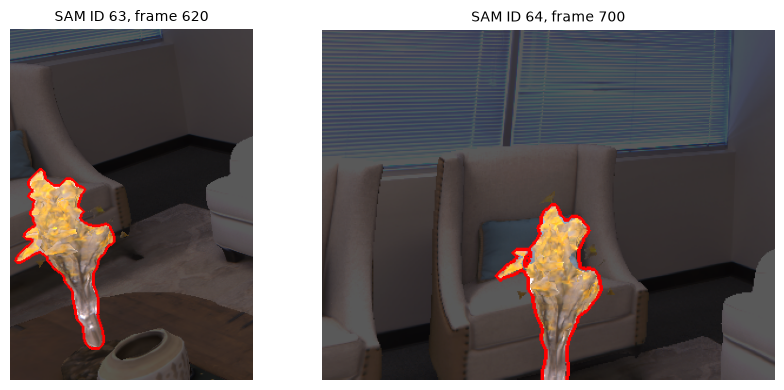

In [13]:
tracks = sorted(first, key=lambda t: first[t]["frame"])[:6]
fig, axes = plt.subplots(1, len(tracks), figsize=(4.5 * len(tracks), 4))
for ax, t in zip(np.atleast_1d(axes), tracks, strict=True):
    frame = first[t]["frame"]
    show_mask(ax, frame, np.flatnonzero((masks.frame == frame) & (masks.sam_id == t)), f"SAM ID {t}, frame {frame}")
fig.tight_layout()

### Every node that holds several SAM IDs

Set `NODE` above to one of these to look at it.

In [14]:
merged = sorted((n for n in nodes if len(n.sam_ids) > 1), key=lambda n: -len(n.frames))
print(f"{len(merged)} of {len(nodes)} nodes hold more than one SAM ID")
for n in merged[:25]:
    size = n.box_max - n.box_min
    print(f"  node {n.id:>3} {n.label:<14} {len(n.frames):>3} frames, SAM IDs {n.sam_ids}, "
          f"box {size[0]:.2f} x {size[1]:.2f} x {size[2]:.2f} m")

113 of 453 nodes hold more than one SAM ID
  node 103 indoor-plant    58 frames, SAM IDs [63, 64], box 0.21 x 0.15 x 0.42 m
  node  92 cushion         57 frames, SAM IDs [54, 55], box 0.34 x 0.33 x 0.35 m
  node 101 sofa            57 frames, SAM IDs [61, 62, 64], box 0.73 x 0.74 x 0.81 m
  node 105 cushion         56 frames, SAM IDs [62, 63], box 0.14 x 1.37 x 0.20 m
  node  99 blinds          55 frames, SAM IDs [60, 61, 69], box 0.02 x 1.35 x 1.62 m
  node 106 cushion         55 frames, SAM IDs [61, 69, 70], box 0.26 x 0.59 x 0.16 m
  node 113 cushion         55 frames, SAM IDs [61, 64, 72, 74, 76], box 0.31 x 0.61 x 0.26 m
  node  87 cushion         54 frames, SAM IDs [55, 56], box 0.32 x 0.32 x 0.32 m
  node 102 vase            53 frames, SAM IDs [66, 69], box 0.04 x 0.04 x 0.22 m
  node 108 blinds          53 frames, SAM IDs [70, 72, 73], box 0.01 x 1.37 x 1.60 m
  node 130 book            53 frames, SAM IDs [24, 27, 76, 78], box 0.18 x 0.19 x 0.02 m
  node 111 chair           52 

## The graph from above

Each node is its 3D box seen from above, over the room's point cloud, in the same colour as in the labelled video.
Set `near=False` to see only the "on" edges.

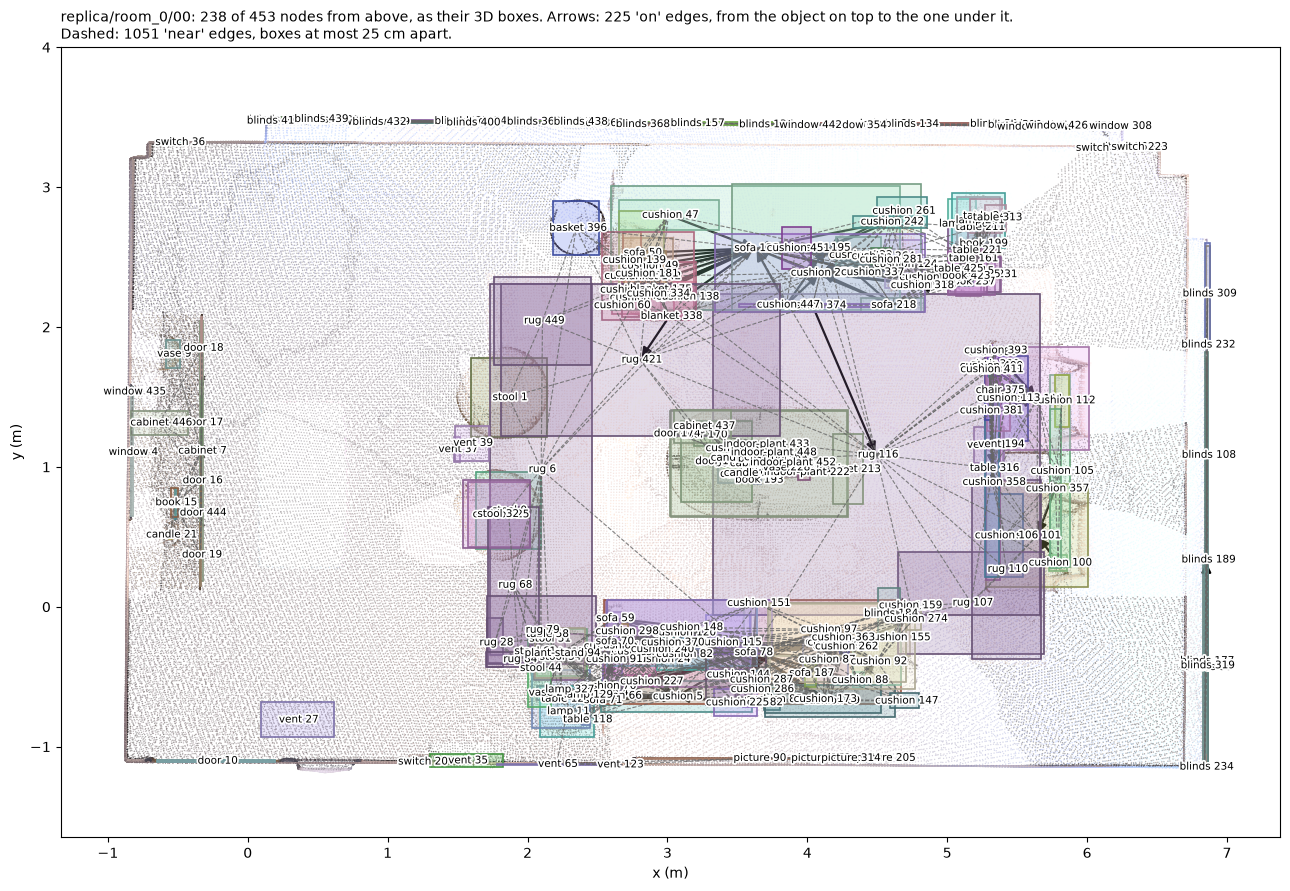

In [15]:
plot_edges.plot(run, near=True);

## The "on" edges

What rests on what. These are the edges that tell similar objects apart: "the cushion on the armchair" rather than
"a cushion".

In [16]:
for e in sorted(edges, key=lambda e: (e.b, e.a)):
    if e.relation == "on":
        print(f"{nodes[e.a].label:>14} {e.a:<3} on  {nodes[e.b].label} {e.b}")

       cushion 25  on  stool 0
         stool 32  on  stool 0
       cushion 41  on  cushion 5
       cushion 66  on  cushion 5
          sofa 71  on  cushion 5
       cushion 182 on  cushion 5
       cushion 225 on  cushion 5
       cushion 227 on  cushion 5
       cushion 40  on  cushion 8
       cushion 8   on  cushion 22
       cushion 31  on  cushion 22
       cushion 40  on  cushion 22
          sofa 59  on  cushion 22
          sofa 70  on  cushion 22
       cushion 80  on  cushion 22
       cushion 82  on  cushion 22
       cushion 91  on  cushion 22
       cushion 115 on  cushion 22
       cushion 144 on  cushion 22
       cushion 240 on  cushion 22
       cushion 298 on  cushion 22
       cushion 370 on  cushion 22
        blinds 438 on  blinds 43
       cushion 334 on  cushion 48
       cushion 45  on  cushion 49
       cushion 64  on  cushion 49
       cushion 139 on  cushion 49
       cushion 45  on  sofa 50
       cushion 64  on  sofa 50
       cushion 139 on  sofa 50
   

## One node and its neighbours

Pick a node ID from the picture above to see its edges and highlight it with its neighbours.

node 37: vent, seen in 1 frames, SAM tracks [38]
  near  vent 39


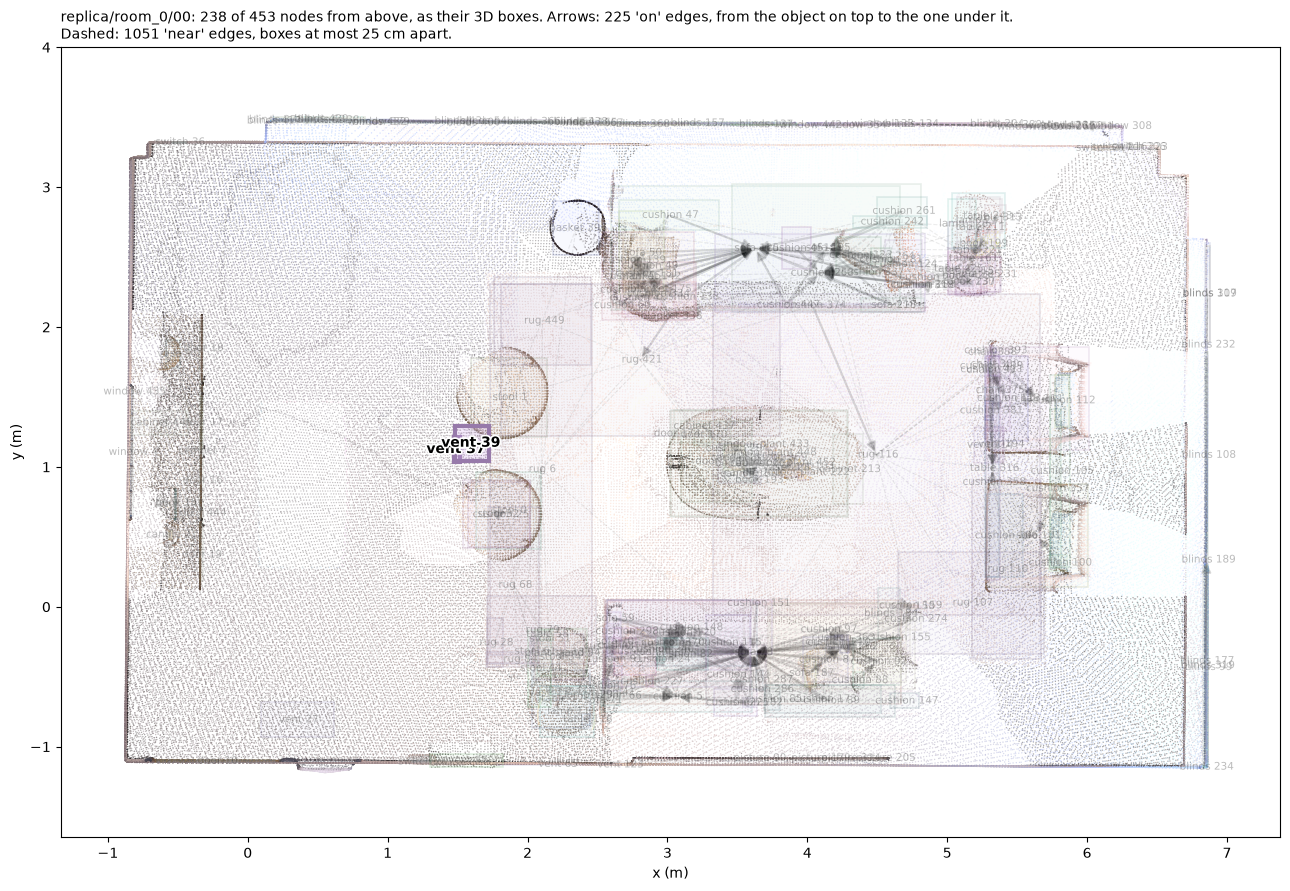

In [17]:
NODE = 37

n = nodes[NODE]
print(f"node {n.id}: {n.label}, seen in {len(n.frames)} frames, SAM tracks {n.sam_ids}")
links = graph_edges.neighbours(edges, NODE)
for relation, other in links:
    print(f"  {relation:<5} {nodes[other].label} {other}")
plot_edges.plot(run, highlight=[NODE] + [other for _, other in links]);

## Nearest object of a type

What `graph.query --near` does: find the object that best matches `NEAR` by SigLIP, then rank the objects of type
`TYPE` by distance to it. The type is the SAM label when `TYPE` is one of the prompts, otherwise SigLIP's best
matches. The anchor and the nearest answer are highlighted.

"sofa": node 125 (sofa)
  cushion 451: 0.00 m apart, 0.29 m between centres
  cushion 447: 0.00 m apart, 0.46 m between centres
  cushion 258: 0.00 m apart, 0.50 m between centres
  cushion 138: 0.00 m apart, 0.61 m between centres
  cushion 47: 0.00 m apart, 0.71 m between centres


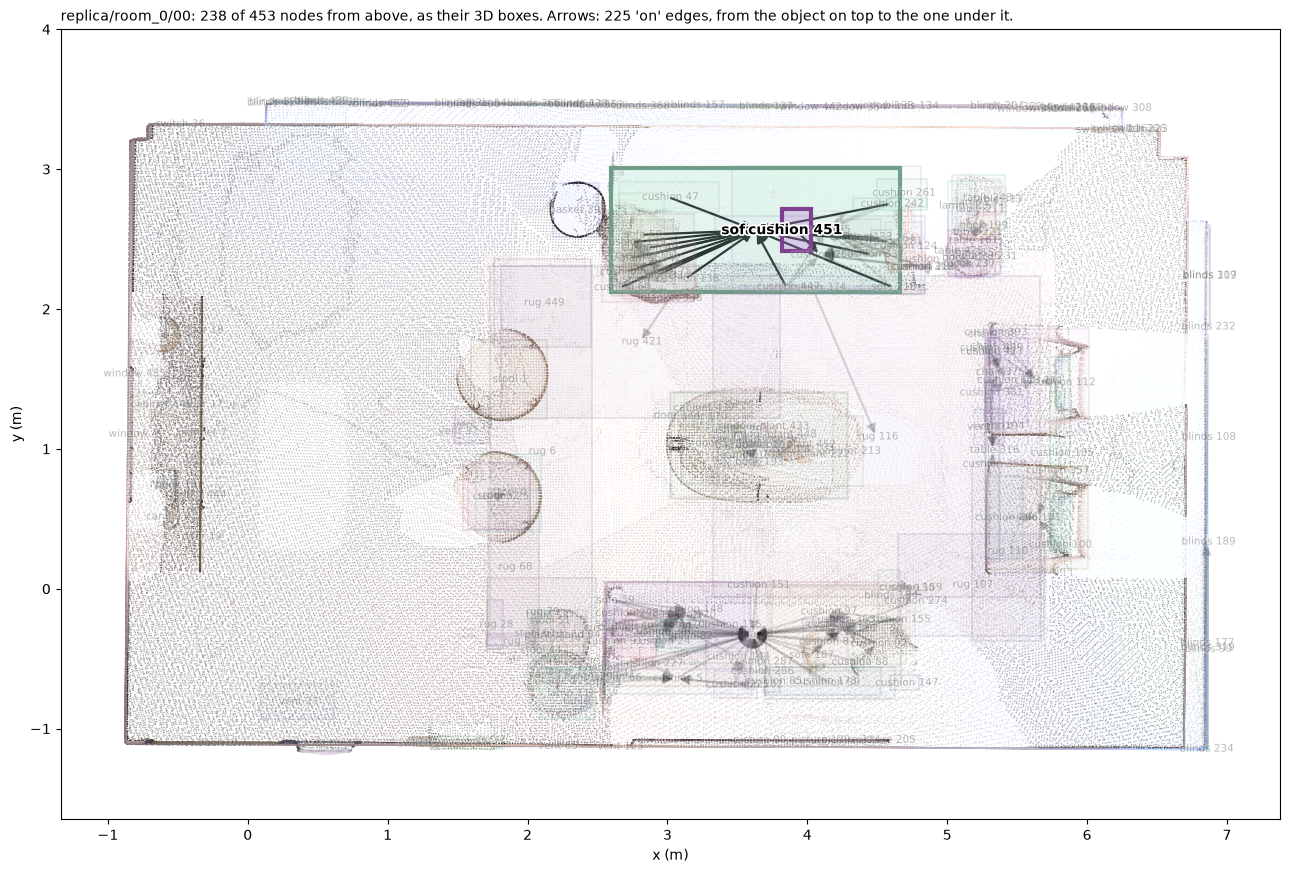

In [18]:
from graph import query
from models import siglip
from utils.schema import Graph, Masks, TextAligned, load_stage

TYPE, NEAR = "cushion", "sofa"

masks = load_stage(run.stage_dir("masks"), Masks)
node_of_mask = load_stage(run.stage_dir("graph"), Graph).node
objects, object_emb = query.object_embeddings(masks, load_stage(run.stage_dir("siglip"), TextAligned), node_of_mask)
sims = siglip.load_encoder().encode_text([TYPE, NEAR]).cpu().numpy() @ object_emb.T
anchor = int(objects[sims[1].argmax()])
rows = query.of_type([nodes[int(o)].label for o in objects], TYPE, sims[0], top=5)
ranked = graph_edges.nearest(nodes, anchor, [int(objects[r]) for r in rows])

print(f'"{NEAR}": node {anchor} ({nodes[anchor].label})')
for node_id, gap, centre in ranked[:5]:
    print(f"  {nodes[node_id].label} {node_id}: {gap:.2f} m apart, {centre:.2f} m between centres")
plot_edges.plot(run, highlight=[anchor, ranked[0][0]] if ranked else [anchor], near=False);

## In 3D

The room's point cloud, the camera path and every object as a labelled box in Rerun. The edges are lines between the
box centres: `world/edges/on` as black arrows and `world/edges/near` in grey. Hide either in the entity tree on the
left, and hover a line for the two objects it joins. Scrub the `frame` timeline to move the camera.

In [19]:
import rerun as rr

from utils import map_view

rr.init("graph")
rr.notebook_show(height=750)
map_view.log_map(run)

HTML(value='<div id="ff757bef-eede-4ef1-a811-b903725b657f"><style onload="eval(atob(\'KGFzeW5jIGZ1bmN0aW9uICgp…

## How well the nearest-object query does

`run.py` scores it against the GT boxes (Replica only, see the README's Evaluation section): for every GT object and
every class with at least two other objects, is the nearest one the map gives the right one?

- **labels**: candidates are the nodes with that SAM label, as above
- **oracle**: candidates are the nodes that stand for an object of that class: only the map's boxes and identities
- **anchor** / **reach**: share of the queries whose anchor is in the map / whose anchor and answer both are

In [20]:
import json

metrics = json.loads((run.stage_dir("eval") / "metrics.json").read_text())
print(f"{'':<18}{'labels':>8}{'oracle':>8}{'anchor':>8}{'reach':>8}{'queries':>9}")
for name, m in metrics.items():
    if "near_labels" in m:
        print(
            f"{name:<18}{m['near_labels']:>8.2f}{m['near_oracle']:>8.2f}{m['near_anchor']:>8.2f}"
            f"{m['near_reach']:>8.2f}{m['near_queries']:>9}"
        )

                    labels  oracle  anchor   reach  queries
tracks, no graph      0.19    0.22    0.70    0.49      716
graph                 0.29    0.52    0.72    0.58      716
